In [9]:
library(report)
library(lme4)
library(lmerTest)
library(BayesFactor)
source('bayesMannWhitney.R')

## Decision Time: Text Summarization

In [10]:
df_iter <- read.csv("processed/decision_time_per_iter.csv")
df_iter <- df_iter[df_iter$domain == "text",]
df_item <- read.csv("processed/decision_time_per_item.csv")
df_item <- df_item[df_item$domain == "text",]
df_iter$interface <- factor(df_iter$interface, levels = c('pointwise', 'pairwise', 'listwise-rating', 'listwise-notie', 'listwise-cantie', 'listwise-ranking'))
df_item$interface <- factor(df_item$interface, levels = c('pointwise', 'pairwise', 'listwise-rating', 'listwise-notie', 'listwise-cantie', 'listwise-ranking'))

In [11]:
# H1
df_iter_pointwise <- df_iter[df_iter$interface == 'pointwise',]
df_iter_pairwise <- df_iter[df_iter$interface == 'pairwise',]
r <- report(wilcox.test(df_iter_pointwise$decision_time, df_iter_pairwise$decision_time))
print(r, verbose=TRUE)

df_item_pointwise <- df_item[df_item$interface == 'pointwise',]
df_item_pairwise <- df_item[df_item$interface == 'pairwise',]
r <- report(wilcox.test(df_item_pointwise$decision_time, df_item_pairwise$decision_time))
print(r, verbose=TRUE)

Effect sizes were labelled following Funder's (2019) recommendations.

The Wilcoxon rank sum test with continuity correction testing the difference in
ranks between df_iter_pointwise$decision_time and
df_iter_pairwise$decision_time suggests that the effect is negative,
statistically not significant, and tiny (W = 2.14e+05, p = 0.168; r (rank
biserial) = -0.04, 95% CI [-0.11, 0.02])
Effect sizes were labelled following Funder's (2019) recommendations.

The Wilcoxon rank sum test with continuity correction testing the difference in
ranks between df_item_pointwise$decision_time and
df_item_pairwise$decision_time suggests that the effect is positive,
statistically significant, and large (W = 2.93e+05, p < .001; r (rank biserial)
= 0.31, 95% CI [0.25, 0.36])


  |**************************************************| 100%

[1] 0.08447456

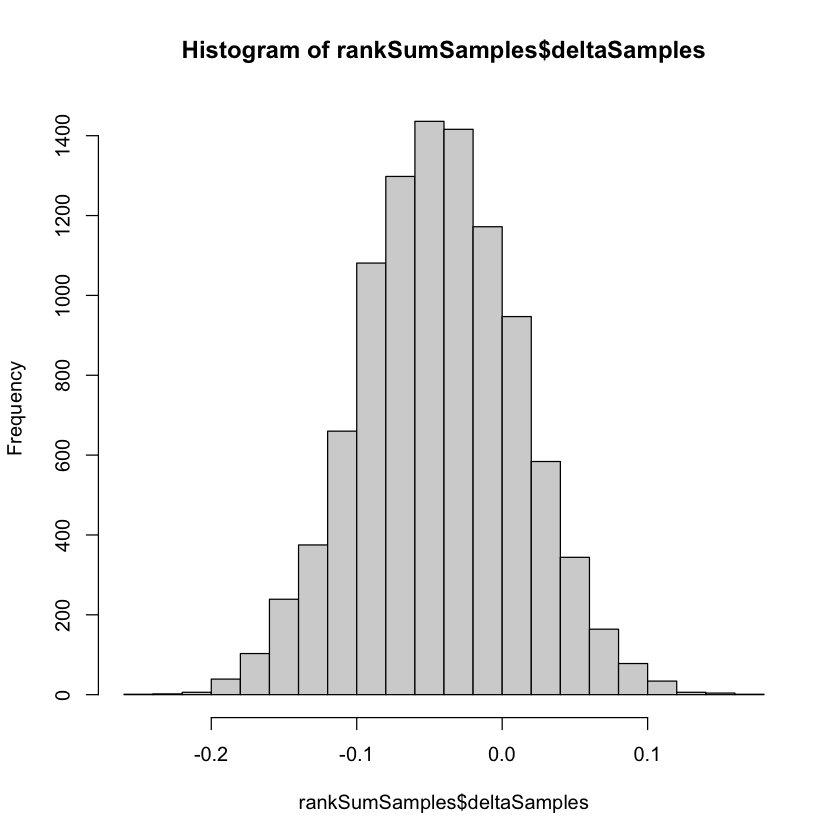

In [12]:
x <- df_iter_pointwise$decision_time
y <- df_iter_pairwise$decision_time

# Default Cauchy prior width is set to 1/sqrt(2) for the sampler 
rankSumSamples <- rankSumGibbsSampler(xVals = x, yVals = y)
hist(rankSumSamples$deltaSamples)
computeBayesFactorOneZero(rankSumSamples$deltaSamples, whichTest = "Wilcoxon", priorParameter = 1 / sqrt(2))

In [13]:
# H2a
df1 <- df_iter[df_iter$interface == 'pointwise',]
df2 <- df_iter[df_iter$interface == 'listwise-rating',]
r <- report(wilcox.test(df1$decision_time, df2$decision_time))
print(r, verbose=TRUE)

df1 <- df_iter[df_iter$interface == 'pairwise',]
df2 <- df_iter[df_iter$interface == 'listwise-cantie',]
r <- report(wilcox.test(df1$decision_time, df2$decision_time))
print(r, verbose=TRUE)

# H2b
df1 <- df_item[df_item$interface == 'pointwise',]
df2 <- df_item[df_item$interface == 'listwise-rating',]
r <- report(wilcox.test(df1$decision_time, df2$decision_time))
print(r, verbose=TRUE)

df1 <- df_item[df_item$interface == 'pairwise',]
df2 <- df_item[df_item$interface == 'listwise-cantie',]
r <- report(wilcox.test(df1$decision_time, df2$decision_time))
print(r, verbose=TRUE)

ttestBF(df1$decision_time, df2$decision_time)

Effect sizes were labelled following Funder's (2019) recommendations.

The Wilcoxon rank sum test with continuity correction testing the difference in
ranks between df1$decision_time and df2$decision_time suggests that the effect
is negative, statistically significant, and medium (W = 1.66e+05, p < .001; r
(rank biserial) = -0.29, 95% CI [-0.34, -0.23])
Effect sizes were labelled following Funder's (2019) recommendations.

The Wilcoxon rank sum test with continuity correction testing the difference in
ranks between df1$decision_time and df2$decision_time suggests that the effect
is negative, statistically significant, and large (W = 1.36e+05, p < .001; r
(rank biserial) = -0.36, 95% CI [-0.41, -0.30])
Effect sizes were labelled following Funder's (2019) recommendations.

The Wilcoxon rank sum test with continuity correction testing the difference in
ranks between df1$decision_time and df2$decision_time suggests that the effect
is positive, statistically significant, and large (W = 3.24

Bayes factor analysis
--------------
[1] Alt., r=0.707 : 0.9083276 ±0.02%

Against denominator:
  Null, mu1-mu2 = 0 
---
Bayes factor type: BFindepSample, JZS


  |**************************************************| 100%

[1] 0.07286307

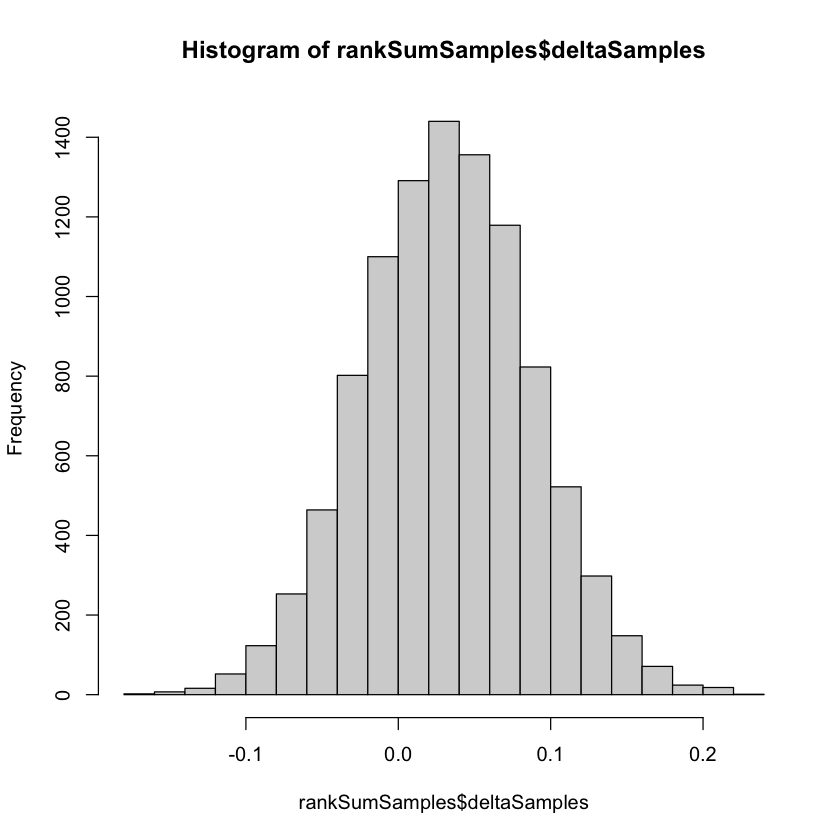

In [14]:
x <- df1$decision_time
y <- df2$decision_time

# Default Cauchy prior width is set to 1/sqrt(2) for the sampler 
rankSumSamples <- rankSumGibbsSampler(xVals = x, yVals = y)
hist(rankSumSamples$deltaSamples)
computeBayesFactorOneZero(rankSumSamples$deltaSamples, whichTest = "Wilcoxon", priorParameter = 1 / sqrt(2))

In [15]:
df_iter <- read.csv("processed/decision_time_per_iter.csv")
df_iter <- df_iter[df_iter$domain == 'text',]
df_item <- read.csv("processed/decision_time_per_item.csv")
df_item <- df_item[df_item$domain == 'text',]

df_iter <- df_iter[df_iter$interface != 'pointwise',]
df_iter <- df_iter[df_iter$interface != 'pairwise',]
df_iter <- df_iter[df_iter$interface != 'listwise-ranking',]
df_item <- df_item[df_item$interface != 'pointwise',]
df_item <- df_item[df_item$interface != 'pairwise',]
df_item <- df_item[df_item$interface != 'listwise-ranking',]

df_iter$interface <- factor(df_iter$interface, levels = c('listwise-cantie', 'listwise-rating', 'listwise-notie'), ordered=FALSE)
df_item$interface <- factor(df_item$interface, levels = c('listwise-cantie', 'listwise-rating', 'listwise-notie'), ordered=FALSE)
# H3a
m <- glmer(decision_time ~ interface + (1|userID), data = df_iter, family = Gamma(link = "inverse"))
summary(m)
print(report(m), verbose=TRUE)
# H3b
m <- glmer(decision_time ~ interface + (1|userID), data = df_item, family = Gamma(link = "inverse"))
summary(m)
print(report(m), verbose=TRUE)

Warning message in checkConv(attr(opt, "derivs"), opt$par, ctrl = control$checkConv, :
“Model failed to converge with max|grad| = 0.00259086 (tol = 0.002, component 1)”
Warning message in checkConv(attr(opt, "derivs"), opt$par, ctrl = control$checkConv, :
“Model is nearly unidentifiable: very large eigenvalue
 - Rescale variables?”


Generalized linear mixed model fit by maximum likelihood (Laplace
  Approximation) [glmerMod]
 Family: Gamma  ( inverse )
Formula: decision_time ~ interface + (1 | userID)
   Data: df_iter

     AIC      BIC   logLik deviance df.resid 
 20710.9  20738.8 -10350.5  20700.9     1937 

Scaled residuals: 
    Min      1Q  Median      3Q     Max 
-0.7374 -0.4944 -0.3077  0.0157 12.6556 

Random effects:
 Groups   Name        Variance  Std.Dev.
 userID   (Intercept) 4.955e-05 0.007039
 Residual             1.736e+00 1.317729
Number of obs: 1942, groups:  userID, 90

Fixed effects:
                           Estimate Std. Error t value Pr(>|z|)    
(Intercept)               0.0146528  0.0011009  13.310   <2e-16 ***
interfacelistwise-rating -0.0008899  0.0015338  -0.580    0.562    
interfacelistwise-notie  -0.0008485  0.0015371  -0.552    0.581    
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Correlation of Fixed Effects:
              (Intr) intrfclstws-r
intrfclstws-r 

We fitted a general linear mixed model (Gamma family with a inverse link)
(estimated using ML and Nelder-Mead optimizer) to predict decision_time with
interface
 (formula: decision_time ~ interface). The model included userID
 as random effect (formula: ~1 | userID). The model's total explanatory power is
very weak (conditional R2 = 2.86e-05) and the part related to the fixed effects
alone (marginal R2) is of 9.91e-08. The model's intercept, corresponding to
interface = listwise-cantie
, is at 0.01 (95% CI [0.01, 0.02], t(1937) = 13.31, p < .001). Within this
model:

  - The effect of interface [listwise-rating] is statistically non-significant
and negative (beta = -8.90e-04, 95% CI [-3.90e-03, 2.12e-03], t(1937) = -0.58,
p = 0.562; Std. beta = -8.90e-04, 95% CI [-3.90e-03, 2.12e-03])
  - The effect of interface [listwise-notie] is statistically non-significant and
negative (beta = -8.49e-04, 95% CI [-3.86e-03, 2.17e-03], t(1937) = -0.55, p =
0.581; Std. beta = -8.49e-04, 95% CI [-3.86

Generalized linear mixed model fit by maximum likelihood (Laplace
  Approximation) [glmerMod]
 Family: Gamma  ( inverse )
Formula: decision_time ~ interface + (1 | userID)
   Data: df_item

     AIC      BIC   logLik deviance df.resid 
 15326.6  15354.4  -7658.3  15316.6     1937 

Scaled residuals: 
    Min      1Q  Median      3Q     Max 
-0.7374 -0.4944 -0.3077  0.0157 12.6556 

Random effects:
 Groups   Name        Variance  Std.Dev.
 userID   (Intercept) 0.0007928 0.02816 
 Residual             1.7364099 1.31773 
Number of obs: 1942, groups:  userID, 90

Fixed effects:
                          Estimate Std. Error t value Pr(>|z|)    
(Intercept)               0.058611   0.004404  13.310   <2e-16 ***
interfacelistwise-rating -0.003560   0.006135  -0.580    0.562    
interfacelistwise-notie  -0.003394   0.006148  -0.552    0.581    
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Correlation of Fixed Effects:
              (Intr) intrfclstws-r
intrfclstws-r -0.7

We fitted a general linear mixed model (Gamma family with a inverse link)
(estimated using ML and Nelder-Mead optimizer) to predict decision_time with
interface
 (formula: decision_time ~ interface). The model included userID
 as random effect (formula: ~1 | userID). The model's total explanatory power is
very weak (conditional R2 = 4.58e-04) and the part related to the fixed effects
alone (marginal R2) is of 1.58e-06. The model's intercept, corresponding to
interface = listwise-cantie
, is at 0.06 (95% CI [0.05, 0.07], t(1937) = 13.31, p < .001). Within this
model:

  - The effect of interface [listwise-rating] is statistically non-significant
and negative (beta = -3.56e-03, 95% CI [-0.02, 8.47e-03], t(1937) = -0.58, p =
0.562; Std. beta = -3.56e-03, 95% CI [-0.02, 8.47e-03])
  - The effect of interface [listwise-notie] is statistically non-significant and
negative (beta = -3.39e-03, 95% CI [-0.02, 8.66e-03], t(1937) = -0.55, p =
0.581; Std. beta = -3.39e-03, 95% CI [-0.02, 8.66e-03])

In [16]:
df_iter <- read.csv("processed/decision_time_per_iter.csv")
df_iter <- df_iter[df_iter$domain == 'text',]
df_item <- read.csv("processed/decision_time_per_item.csv")
df_item <- df_item[df_item$domain == 'text',]

df_iter <- df_iter[df_iter$interface != 'pointwise',]
df_item <- df_item[df_item$interface != 'pointwise',]

df_iter$interface <- factor(df_iter$interface, levels = c('listwise-ranking', 'pairwise', 'listwise-rating', 'listwise-notie', 'listwise-cantie'), ordered=FALSE)
df_item$interface <- factor(df_item$interface, levels = c('listwise-ranking', 'pairwise', 'listwise-rating', 'listwise-notie', 'listwise-cantie'), ordered=FALSE)
# H4
m <- glmer(decision_time ~ interface + (1|userID), data = df_iter, family = Gamma(link = "inverse"))
summary(m)
print(report(m), verbose=TRUE)
m <- glmer(decision_time ~ interface + (1|userID), data = df_item, family = Gamma(link = "inverse"))
summary(m)
print(report(m), verbose=TRUE)

Warning message in checkConv(attr(opt, "derivs"), opt$par, ctrl = control$checkConv, :
“Model failed to converge with max|grad| = 0.00209924 (tol = 0.002, component 1)”
Warning message in checkConv(attr(opt, "derivs"), opt$par, ctrl = control$checkConv, :
“Model is nearly unidentifiable: very large eigenvalue
 - Rescale variables?”


Generalized linear mixed model fit by maximum likelihood (Laplace
  Approximation) [glmerMod]
 Family: Gamma  ( inverse )
Formula: decision_time ~ interface + (1 | userID)
   Data: df_iter

     AIC      BIC   logLik deviance df.resid 
 33183.0  33225.5 -16584.5  33169.0     3166 

Scaled residuals: 
    Min      1Q  Median      3Q     Max 
-0.7557 -0.5099 -0.3164  0.0351 12.8784 

Random effects:
 Groups   Name        Variance  Std.Dev.
 userID   (Intercept) 7.439e-05 0.008625
 Residual             1.688e+00 1.299318
Number of obs: 3173, groups:  userID, 150

Fixed effects:
                           Estimate Std. Error t value Pr(>|z|)    
(Intercept)               0.0145973  0.0013243  11.023  < 2e-16 ***
interfacepairwise         0.0099521  0.0019823   5.021 5.15e-07 ***
interfacelistwise-rating -0.0006681  0.0018519  -0.361    0.718    
interfacelistwise-notie  -0.0005030  0.0018571  -0.271    0.787    
interfacelistwise-cantie  0.0003687  0.0018576   0.198    0.843    
---
Signif

We fitted a general linear mixed model (Gamma family with a inverse link)
(estimated using ML and Nelder-Mead optimizer) to predict decision_time with
interface
 (formula: decision_time ~ interface). The model included userID
 as random effect (formula: ~1 | userID). The model's total explanatory power is
very weak (conditional R2 = 5.38e-05) and the part related to the fixed effects
alone (marginal R2) is of 9.75e-06. The model's intercept, corresponding to
interface = listwise-ranking
, is at 0.01 (95% CI [0.01, 0.02], t(3166) = 11.02, p < .001). Within this
model:

  - The effect of interface [pairwise] is statistically significant and positive
(beta = 9.95e-03, 95% CI [6.07e-03, 0.01], t(3166) = 5.02, p < .001; Std. beta
= 9.95e-03, 95% CI [6.07e-03, 0.01])
  - The effect of interface [listwise-rating] is statistically non-significant
and negative (beta = -6.68e-04, 95% CI [-4.30e-03, 2.96e-03], t(3166) = -0.36,
p = 0.718; Std. beta = -6.68e-04, 95% CI [-4.30e-03, 2.96e-03])
  - Th

Generalized linear mixed model fit by maximum likelihood (Laplace
  Approximation) [glmerMod]
 Family: Gamma  ( inverse )
Formula: decision_time ~ interface + (1 | userID)
   Data: df_item

     AIC      BIC   logLik deviance df.resid 
 25239.0  25281.4 -12612.5  25225.0     3166 

Scaled residuals: 
    Min      1Q  Median      3Q     Max 
-0.7597 -0.5122 -0.3187  0.0325 12.8549 

Random effects:
 Groups   Name        Variance  Std.Dev.
 userID   (Intercept) 0.0008633 0.02938 
 Residual             1.6739630 1.29382 
Number of obs: 3173, groups:  userID, 150

Fixed effects:
                          Estimate Std. Error t value Pr(>|z|)    
(Intercept)               0.057363   0.004642  12.358   <2e-16 ***
interfacepairwise        -0.004757   0.006461  -0.736    0.462    
interfacelistwise-rating -0.002120   0.006477  -0.327    0.743    
interfacelistwise-notie  -0.001821   0.006493  -0.281    0.779    
interfacelistwise-cantie  0.001598   0.006497   0.246    0.806    
---
Signif. code

We fitted a general linear mixed model (Gamma family with a inverse link)
(estimated using ML and Nelder-Mead optimizer) to predict decision_time with
interface
 (formula: decision_time ~ interface). The model included userID
 as random effect (formula: ~1 | userID). The model's total explanatory power is
very weak (conditional R2 = 5.18e-04) and the part related to the fixed effects
alone (marginal R2) is of 2.78e-06. The model's intercept, corresponding to
interface = listwise-ranking
, is at 0.06 (95% CI [0.05, 0.07], t(3166) = 12.36, p < .001). Within this
model:

  - The effect of interface [pairwise] is statistically non-significant and
negative (beta = -4.76e-03, 95% CI [-0.02, 7.91e-03], t(3166) = -0.74, p =
0.462; Std. beta = -4.76e-03, 95% CI [-0.02, 7.91e-03])
  - The effect of interface [listwise-rating] is statistically non-significant
and negative (beta = -2.12e-03, 95% CI [-0.01, 0.01], t(3166) = -0.33, p =
0.743; Std. beta = -2.12e-03, 95% CI [-0.01, 0.01])
  - The effe

## Decision Time: Photo Color Enhancement

In [17]:
df_iter <- read.csv("processed/decision_time_per_iter.csv")
df_iter <- df_iter[df_iter$domain == "image",]
df_item <- read.csv("processed/decision_time_per_item.csv")
df_item <- df_item[df_item$domain == "image",]
df_iter$interface <- factor(df_iter$interface, levels = c('pointwise', 'pairwise', 'listwise-rating', 'listwise-notie', 'listwise-cantie', 'listwise-ranking'))
df_item$interface <- factor(df_item$interface, levels = c('pointwise', 'pairwise', 'listwise-rating', 'listwise-notie', 'listwise-cantie', 'listwise-ranking'))

In [18]:
# H1
df_iter_pointwise <- df_iter[df_iter$interface == 'pointwise',]
df_iter_pairwise <- df_iter[df_iter$interface == 'pairwise',]
r <- report(wilcox.test(df_iter_pointwise$decision_time, df_iter_pairwise$decision_time))
print(r, verbose=TRUE)

df_item_pointwise <- df_item[df_item$interface == 'pointwise',]
df_item_pairwise <- df_item[df_item$interface == 'pairwise',]
r <- report(wilcox.test(df_item_pointwise$decision_time, df_item_pairwise$decision_time))
print(r, verbose=TRUE)

Effect sizes were labelled following Funder's (2019) recommendations.

The Wilcoxon rank sum test with continuity correction testing the difference in
ranks between df_iter_pointwise$decision_time and
df_iter_pairwise$decision_time suggests that the effect is positive,
statistically significant, and medium (W = 5.75e+05, p < .001; r (rank
biserial) = 0.29, 95% CI [0.24, 0.34])
Effect sizes were labelled following Funder's (2019) recommendations.

The Wilcoxon rank sum test with continuity correction testing the difference in
ranks between df_item_pointwise$decision_time and
df_item_pairwise$decision_time suggests that the effect is positive,
statistically significant, and very large (W = 7.39e+05, p < .001; r (rank
biserial) = 0.66, 95% CI [0.63, 0.69])


  |**************************************************| 100%

[1] 1.980155e+12

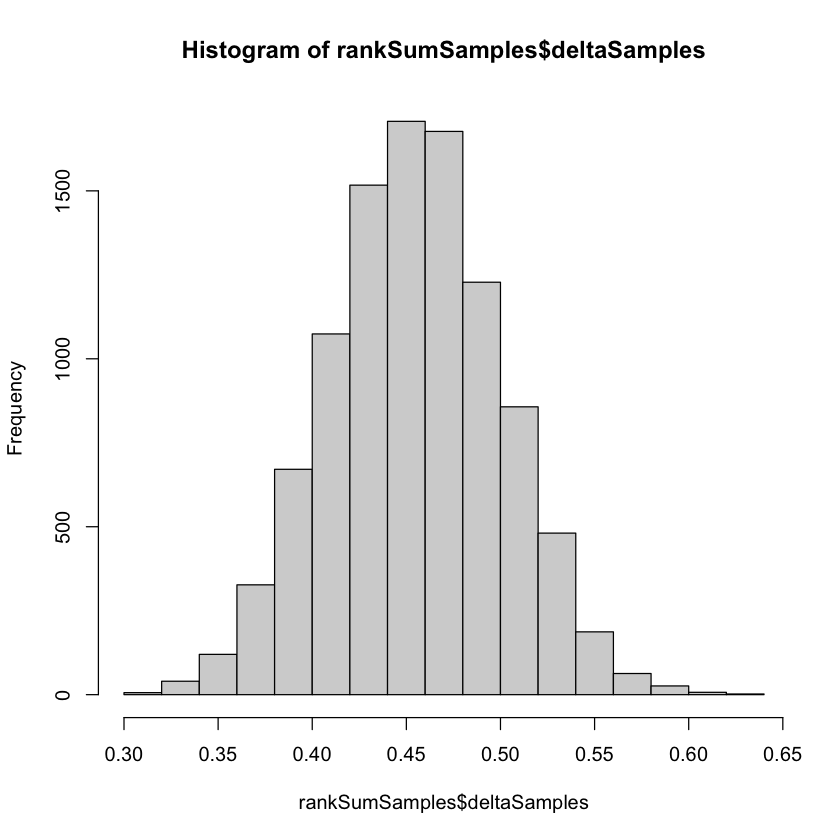

In [19]:
x <- df_iter_pointwise$decision_time
y <- df_iter_pairwise$decision_time

# Default Cauchy prior width is set to 1/sqrt(2) for the sampler 
rankSumSamples <- rankSumGibbsSampler(xVals = x, yVals = y)
hist(rankSumSamples$deltaSamples)
computeBayesFactorOneZero(rankSumSamples$deltaSamples, whichTest = "Wilcoxon", priorParameter = 1 / sqrt(2))

In [20]:
# H2a
df1 <- df_iter[df_iter$interface == 'pointwise',]
df2 <- df_iter[df_iter$interface == 'listwise-rating',]
r <- report(wilcox.test(df1$decision_time, df2$decision_time))
print(r, verbose=TRUE)

df1 <- df_iter[df_iter$interface == 'pairwise',]
df2 <- df_iter[df_iter$interface == 'listwise-cantie',]
r <- report(wilcox.test(df1$decision_time, df2$decision_time))
print(r, verbose=TRUE)

# H2b
df1 <- df_item[df_item$interface == 'pointwise',]
df2 <- df_item[df_item$interface == 'listwise-rating',]
r <- report(wilcox.test(df1$decision_time, df2$decision_time))
print(r, verbose=TRUE)

df1 <- df_item[df_item$interface == 'pairwise',]
df2 <- df_item[df_item$interface == 'listwise-cantie',]
r <- report(wilcox.test(df1$decision_time, df2$decision_time))
print(r, verbose=TRUE)

ttestBF(df1$decision_time, df2$decision_time)

Effect sizes were labelled following Funder's (2019) recommendations.

The Wilcoxon rank sum test with continuity correction testing the difference in
ranks between df1$decision_time and df2$decision_time suggests that the effect
is negative, statistically significant, and very large (W = 2.07e+05, p < .001;
r (rank biserial) = -0.48, 95% CI [-0.52, -0.44])
Effect sizes were labelled following Funder's (2019) recommendations.

The Wilcoxon rank sum test with continuity correction testing the difference in
ranks between df1$decision_time and df2$decision_time suggests that the effect
is negative, statistically significant, and very large (W = 67358.50, p < .001;
r (rank biserial) = -0.80, 95% CI [-0.82, -0.78])
Effect sizes were labelled following Funder's (2019) recommendations.

The Wilcoxon rank sum test with continuity correction testing the difference in
ranks between df1$decision_time and df2$decision_time suggests that the effect
is positive, statistically significant, and very l

Bayes factor analysis
--------------
[1] Alt., r=0.707 : 4.509452 ±0%

Against denominator:
  Null, mu1-mu2 = 0 
---
Bayes factor type: BFindepSample, JZS


  |**************************************************| 100%

[1] 1.062895e+14

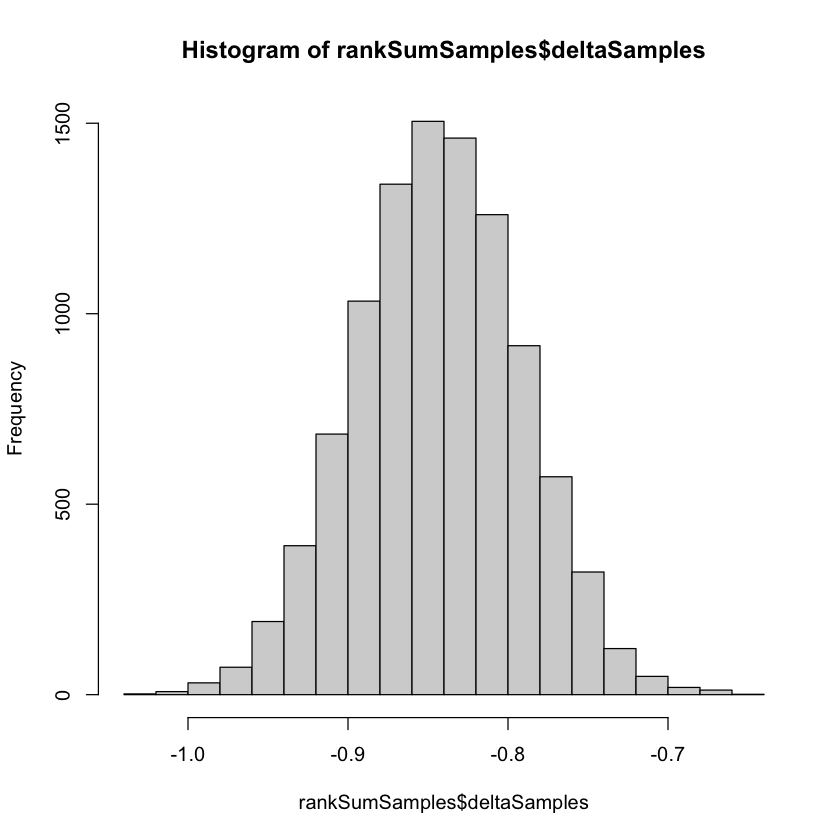

In [21]:
x <- df1$decision_time
y <- df2$decision_time

# Default Cauchy prior width is set to 1/sqrt(2) for the sampler 
rankSumSamples <- rankSumGibbsSampler(xVals = x, yVals = y)
hist(rankSumSamples$deltaSamples)
computeBayesFactorOneZero(rankSumSamples$deltaSamples, whichTest = "Wilcoxon", priorParameter = 1 / sqrt(2))

In [22]:
df_iter <- read.csv("processed/decision_time_per_iter.csv")
df_iter <- df_iter[df_iter$domain == 'image',]
df_item <- read.csv("processed/decision_time_per_item.csv")
df_item <- df_item[df_item$domain == 'image',]

df_iter <- df_iter[df_iter$interface != 'pointwise',]
df_iter <- df_iter[df_iter$interface != 'pairwise',]
df_iter <- df_iter[df_iter$interface != 'listwise-ranking',]
df_item <- df_item[df_item$interface != 'pointwise',]
df_item <- df_item[df_item$interface != 'pairwise',]
df_item <- df_item[df_item$interface != 'listwise-ranking',]

df_iter$interface <- factor(df_iter$interface, levels = c('listwise-cantie', 'listwise-rating', 'listwise-notie'), ordered=FALSE)
df_item$interface <- factor(df_item$interface, levels = c('listwise-cantie', 'listwise-rating', 'listwise-notie'), ordered=FALSE)
# H3a
m <- glmer(decision_time ~ interface + (1|userID), data = df_iter, family = Gamma(link = "inverse"))
summary(m)
print(report(m), verbose=TRUE)
# H3b
m <- glmer(decision_time ~ interface + (1|userID), data = df_item, family = Gamma(link = "inverse"))
summary(m)
print(report(m), verbose=TRUE)

Generalized linear mixed model fit by maximum likelihood (Laplace
  Approximation) [glmerMod]
 Family: Gamma  ( inverse )
Formula: decision_time ~ interface + (1 | userID)
   Data: df_iter

     AIC      BIC   logLik deviance df.resid 
 18542.3  18571.0  -9266.1  18532.3     2305 

Scaled residuals: 
    Min      1Q  Median      3Q     Max 
-0.7722 -0.4400 -0.2613  0.0379 13.8878 

Random effects:
 Groups   Name        Variance  Std.Dev.
 userID   (Intercept) 0.0004901 0.02214 
 Residual             1.1740099 1.08352 
Number of obs: 2310, groups:  userID, 90

Fixed effects:
                           Estimate Std. Error t value Pr(>|z|)    
(Intercept)               0.0457145  0.0037564  12.170   <2e-16 ***
interfacelistwise-rating  0.0052730  0.0053037   0.994     0.32    
interfacelistwise-notie  -0.0005295  0.0052824  -0.100     0.92    
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Correlation of Fixed Effects:
              (Intr) intrfclstws-r
intrfclstws-r 

We fitted a general linear mixed model (Gamma family with a inverse link)
(estimated using ML and Nelder-Mead optimizer) to predict decision_time with
interface
 (formula: decision_time ~ interface). The model included userID
 as random effect (formula: ~1 | userID). The model's total explanatory power is
very weak (conditional R2 = 4.23e-04) and the part related to the fixed effects
alone (marginal R2) is of 5.90e-06. The model's intercept, corresponding to
interface = listwise-cantie
, is at 0.05 (95% CI [0.04, 0.05], t(2305) = 12.17, p < .001). Within this
model:

  - The effect of interface [listwise-rating] is statistically non-significant
and positive (beta = 5.27e-03, 95% CI [-5.13e-03, 0.02], t(2305) = 0.99, p =
0.320; Std. beta = 5.27e-03, 95% CI [-5.13e-03, 0.02])
  - The effect of interface [listwise-notie] is statistically non-significant and
negative (beta = -5.30e-04, 95% CI [-0.01, 9.83e-03], t(2305) = -0.10, p =
0.920; Std. beta = -5.30e-04, 95% CI [-0.01, 9.83e-03])

S

Generalized linear mixed model fit by maximum likelihood (Laplace
  Approximation) [glmerMod]
 Family: Gamma  ( inverse )
Formula: decision_time ~ interface + (1 | userID)
   Data: df_item

     AIC      BIC   logLik deviance df.resid 
 12137.6  12166.3  -6063.8  12127.6     2305 

Scaled residuals: 
    Min      1Q  Median      3Q     Max 
-0.7722 -0.4400 -0.2613  0.0379 13.8878 

Random effects:
 Groups   Name        Variance Std.Dev.
 userID   (Intercept) 0.007842 0.08856 
 Residual             1.174010 1.08352 
Number of obs: 2310, groups:  userID, 90

Fixed effects:
                          Estimate Std. Error t value Pr(>|z|)    
(Intercept)               0.182858   0.015025  12.170   <2e-16 ***
interfacelistwise-rating  0.021093   0.021215   0.994     0.32    
interfacelistwise-notie  -0.002118   0.021129  -0.100     0.92    
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Correlation of Fixed Effects:
              (Intr) intrfclstws-r
intrfclstws-r -0.704 

We fitted a general linear mixed model (Gamma family with a inverse link)
(estimated using ML and Nelder-Mead optimizer) to predict decision_time with
interface
 (formula: decision_time ~ interface). The model included userID
 as random effect (formula: ~1 | userID). The model's total explanatory power is
very weak (conditional R2 = 6.73e-03) and the part related to the fixed effects
alone (marginal R2) is of 9.38e-05. The model's intercept, corresponding to
interface = listwise-cantie
, is at 0.18 (95% CI [0.15, 0.21], t(2305) = 12.17, p < .001). Within this
model:

  - The effect of interface [listwise-rating] is statistically non-significant
and positive (beta = 0.02, 95% CI [-0.02, 0.06], t(2305) = 0.99, p = 0.320;
Std. beta = 0.02, 95% CI [-0.02, 0.06])
  - The effect of interface [listwise-notie] is statistically non-significant and
negative (beta = -2.12e-03, 95% CI [-0.04, 0.04], t(2305) = -0.10, p = 0.920;
Std. beta = -2.12e-03, 95% CI [-0.04, 0.04])

Standardized parameters w

In [23]:
df_iter <- read.csv("processed/decision_time_per_iter.csv")
df_iter <- df_iter[df_iter$domain == 'image',]
df_item <- read.csv("processed/decision_time_per_item.csv")
df_item <- df_item[df_item$domain == 'image',]

df_iter <- df_iter[df_iter$interface != 'pointwise',]
df_item <- df_item[df_item$interface != 'pointwise',]

df_iter$interface <- factor(df_iter$interface, levels = c('listwise-ranking', 'pairwise', 'listwise-rating', 'listwise-notie', 'listwise-cantie'), ordered=FALSE)
df_item$interface <- factor(df_item$interface, levels = c('listwise-ranking', 'pairwise', 'listwise-rating', 'listwise-notie', 'listwise-cantie'), ordered=FALSE)
# H4
m <- glmer(decision_time ~ interface + (1|userID), data = df_iter, family = Gamma(link = "inverse"))
summary(m)
print(report(m), verbose=TRUE)
m <- glmer(decision_time ~ interface + (1|userID), data = df_item, family = Gamma(link = "inverse"))
summary(m)
print(report(m), verbose=TRUE)

Warning message in checkConv(attr(opt, "derivs"), opt$par, ctrl = control$checkConv, :
“Model failed to converge with max|grad| = 0.0811091 (tol = 0.002, component 1)”
Warning message in checkConv(attr(opt, "derivs"), opt$par, ctrl = control$checkConv, :
“Model is nearly unidentifiable: very large eigenvalue
 - Rescale variables?”


Generalized linear mixed model fit by maximum likelihood (Laplace
  Approximation) [glmerMod]
 Family: Gamma  ( inverse )
Formula: decision_time ~ interface + (1 | userID)
   Data: df_iter

     AIC      BIC   logLik deviance df.resid 
 30579.7  30623.9 -15282.9  30565.7     4023 

Scaled residuals: 
    Min      1Q  Median      3Q     Max 
-0.9068 -0.4612 -0.2653  0.0425 14.0570 

Random effects:
 Groups   Name        Variance Std.Dev.
 userID   (Intercept) 0.001158 0.03403 
 Residual             1.142671 1.06896 
Number of obs: 4030, groups:  userID, 150

Fixed effects:
                           Estimate Std. Error t value Pr(>|z|)    
(Intercept)               4.624e-02  1.025e-03  45.100  < 2e-16 ***
interfacepairwise         9.547e-02  1.086e-03  87.911  < 2e-16 ***
interfacelistwise-rating  5.364e-03  1.076e-03   4.984 6.22e-07 ***
interfacelistwise-notie  -3.429e-04  1.076e-03  -0.319    0.750    
interfacelistwise-cantie  4.785e-05  1.076e-03   0.044    0.965    
---
Signif. c

We fitted a general linear mixed model (Gamma family with a inverse link)
(estimated using ML and Nelder-Mead optimizer) to predict decision_time with
interface
 (formula: decision_time ~ interface). The model included userID
 as random effect (formula: ~1 | userID). The model's total explanatory power is
very weak (conditional R2 = 2.33e-03) and the part related to the fixed effects
alone (marginal R2) is of 1.32e-03. The model's intercept, corresponding to
interface = listwise-ranking
, is at 0.05 (95% CI [0.04, 0.05], t(4023) = 45.10, p < .001). Within this
model:

  - The effect of interface [pairwise] is statistically significant and positive
(beta = 0.10, 95% CI [0.09, 0.10], t(4023) = 87.91, p < .001; Std. beta = 0.10,
95% CI [0.09, 0.10])
  - The effect of interface [listwise-rating] is statistically significant and
positive (beta = 5.36e-03, 95% CI [3.25e-03, 7.47e-03], t(4023) = 4.98, p <
.001; Std. beta = 5.36e-03, 95% CI [3.25e-03, 7.47e-03])
  - The effect of interface [li

Generalized linear mixed model fit by maximum likelihood (Laplace
  Approximation) [glmerMod]
 Family: Gamma  ( inverse )
Formula: decision_time ~ interface + (1 | userID)
   Data: df_item

     AIC      BIC   logLik deviance df.resid 
 20550.3  20594.4 -10268.1  20536.3     4023 

Scaled residuals: 
    Min      1Q  Median      3Q     Max 
-0.9094 -0.4577 -0.2701  0.0417 13.9464 

Random effects:
 Groups   Name        Variance Std.Dev.
 userID   (Intercept) 0.009814 0.09907 
 Residual             1.139792 1.06761 
Number of obs: 4030, groups:  userID, 150

Fixed effects:
                           Estimate Std. Error t value Pr(>|z|)    
(Intercept)               0.1832391  0.0169813  10.791  < 2e-16 ***
interfacepairwise         0.1117108  0.0244351   4.572 4.84e-06 ***
interfacelistwise-rating  0.0217381  0.0241192   0.901    0.367    
interfacelistwise-notie  -0.0018411  0.0240282  -0.077    0.939    
interfacelistwise-cantie  0.0005192  0.0240919   0.022    0.983    
---
Signif. c

We fitted a general linear mixed model (Gamma family with a inverse link)
(estimated using ML and Nelder-Mead optimizer) to predict decision_time with
interface
 (formula: decision_time ~ interface). The model included userID
 as random effect (formula: ~1 | userID). The model's total explanatory power is
very weak (conditional R2 = 0.01) and the part related to the fixed effects
alone (marginal R2) is of 1.74e-03. The model's intercept, corresponding to
interface = listwise-ranking
, is at 0.18 (95% CI [0.15, 0.22], t(4023) = 10.79, p < .001). Within this
model:

  - The effect of interface [pairwise] is statistically significant and positive
(beta = 0.11, 95% CI [0.06, 0.16], t(4023) = 4.57, p < .001; Std. beta = 0.11,
95% CI [0.06, 0.16])
  - The effect of interface [listwise-rating] is statistically non-significant
and positive (beta = 0.02, 95% CI [-0.03, 0.07], t(4023) = 0.90, p = 0.367;
Std. beta = 0.02, 95% CI [-0.03, 0.07])
  - The effect of interface [listwise-notie] is stati